In [5]:
!pip install -q kaggle

In [6]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle connected successfully!")

Kaggle connected successfully!


In [7]:
!kaggle datasets list

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [8]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 3.1 MB/s eta 0:00:00


In [9]:
import os
os.environ['KAGGLE_API_TOKEN'] = 'PASTE_YOUR_KAGGLE_TOKEN_HERE'
!pip install -q --upgrade kaggle

In [10]:
!kaggle dataset list

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
usage: kaggle [-h] [-v] [-W]
              {competitions,c,datasets,d,kernels,k,models,m,files,forums,f,benchmarks,b,config,auth,quota} ...
kaggle: error: argument command: invalid choice: 'dataset' (choose from 'competitions', 'c', 'datasets', 'd', 'kernels', 'k', 'models', 'm', 'files', 'forums', 'f', 'benchmarks', 'b', 'config',

In [11]:
from google.colab import files
files.upload()   # kaggle.json select karo

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving archive (1).zip to archive (1).zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [12]:
import json, os

kaggle_creds = {
    "username": "YOUR_KAGGLE_USERNAME",
    "key": "YOUR_TOKEN_HERE"
}

os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(kaggle_creds, f)

!chmod 600 /root/.kaggle/kaggle.json

In [13]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle token connected!")

Kaggle token connected!


In [14]:
import os

print(os.listdir("/content"))

['.config', 'archive (1).zip', 'sample_data']


In [16]:
import zipfile
import os

zip_path = "/content/archive (1).zip"
extract_path = "/content/smart_classroom"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction complete!")
print(os.listdir(extract_path))

Extraction complete!
['ANN_Project_pics']


In [17]:
import os

dataset_path = "/content/smart_classroom/ANN_Project_pics"

print("Folders:")
print(os.listdir(dataset_path))

for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)
    if os.path.isdir(folder_path):
        print(folder, "=", len(os.listdir(folder_path)), "files")

Folders:
['moderate dirty', 'Clean', 'Dirty']
moderate dirty = 51 files
Clean = 94 files
Dirty = 59 files


In [18]:
import tensorflow as tf

dataset_path = "/content/smart_classroom/ANN_Project_pics"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Classes:", train_data.class_names)

Found 121 files belonging to 3 classes.
Using 97 files for training.
Found 121 files belonging to 3 classes.
Using 24 files for validation.
Classes: ['Clean', 'Dirty', 'moderate dirty']


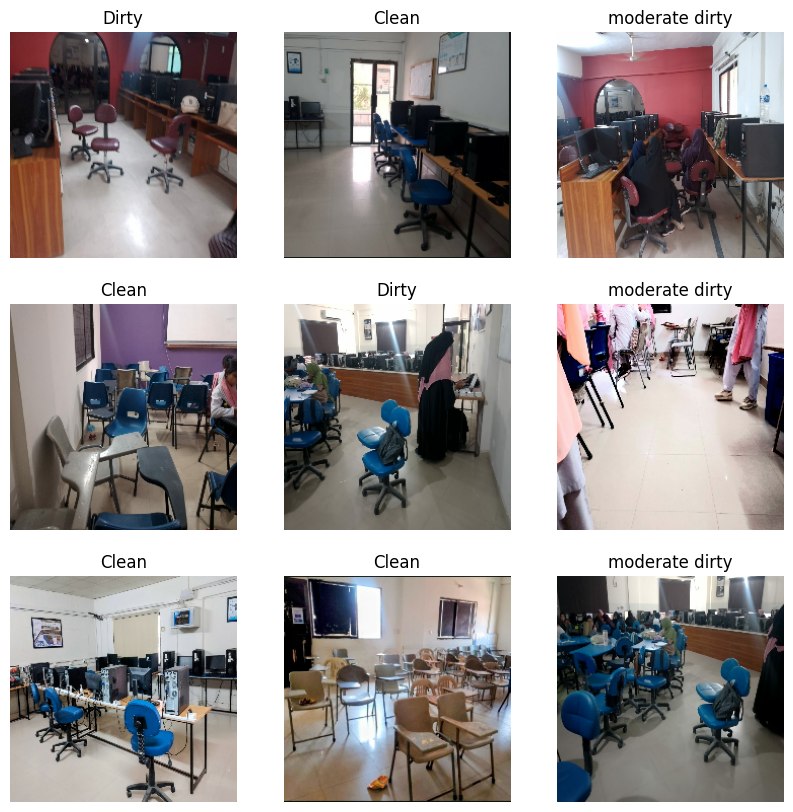

In [28]:
import matplotlib.pyplot as plt

# Correct variable names to match train_ds
class_names = ['Clean', 'Dirty', 'moderate dirty']

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        # Convert back to uint8 if normalized, otherwise use as-is
        img_val = images[i].numpy()
        if img_val.max() <= 1.0:
            img_val = (img_val * 255).astype("uint8")
        else:
            img_val = img_val.astype("uint8")
        plt.imshow(img_val)
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [50]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',
                           input_shape=(224, 224, 3)),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(3, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_data = train_data.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_data = validation_data.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Normalization complete!")

Normalization complete!


In [26]:
model.save("/content/smart_classroom_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [28]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_data = train_data.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_data = validation_data.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Normalization complete!")

Normalization complete!


In [29]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu',
                           input_shape=(224, 224, 3)),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(3, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

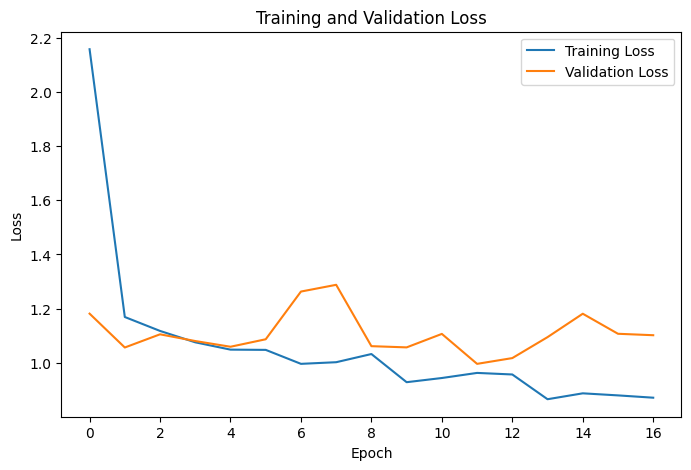

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training Loss', 'Validation Loss'])

plt.show()

In [31]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true = []
y_pred = []

for images, labels in validation_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 0  4  0]
 [ 0  9  0]
 [ 0 11  0]]


In [32]:
class_names = ['Clean', 'Dirty', 'moderate dirty']

print(class_names)

['Clean', 'Dirty', 'moderate dirty']


In [33]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

                precision    recall  f1-score   support

         Clean       0.00      0.00      0.00         4
         Dirty       0.38      1.00      0.55         9
moderate dirty       0.00      0.00      0.00        11

      accuracy                           0.38        24
     macro avg       0.12      0.33      0.18        24
  weighted avg       0.14      0.38      0.20        24



In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(3), class_names, rotation=45)
plt.yticks(range(3), class_names)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [1]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import zipfile
import os

zip_file = "/content/image_tes.zip"
extract_path = "/content/test_img_2"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")
print(os.listdir(extract_path))

In [ ]:
import os

folder = "/content/test_img_2/test_img_2"

print("Files:")
print(os.listdir(folder))

In [ ]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

# Extracted folder
base_folder = "/content/test_img_2"

# Saari images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total test images:", len(image_files))
print("Images:", image_files)

In [ ]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

base_folder = "/content/test_img_2"

# Images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))
print()

# Har image ki prediction
for file_name in image_files:

    img = tf.keras.utils.load_img(
        file_name,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("Image:", os.path.basename(file_name))
    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")
    print("-----------------------------")

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

### Step 1: Define Transfer Learning Model with MobileNetV2

In [ ]:
import tensorflow as tf
import os
import zipfile

dataset_path = "/content/smart_classroom/ANN_Project_pics"
zip_path = "/content/archive (1).zip"

# Extract archive (1).zip to /content/smart_classroom
if not os.path.exists(dataset_path):
    if os.path.exists(zip_path):
        print(f"Extracting dataset from {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("/content/smart_classroom")
        print("Extraction complete!")
    else:
        raise FileNotFoundError(f"Expected zip file not found at {zip_path}. Please re-upload.")
else:
    print("Dataset folder already exists.")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

# Create train_ds and val_ds datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Configure datasets for optimal performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

### Run this cell to upload your `archive (2).zip` file directly:

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
# Robust Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
])

# MobileNetV2 preprocessing layer (scales inputs from [0, 255] to [-1, 1])
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Load base model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # Freeze the pre-trained weights

# Build the final model
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)  # Ensure batchnorm runs in inference mode
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)  # Dropout to prevent overfitting
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)

transfer_model = tf.keras.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

### Step 2: Train the Model with Early Stopping

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True
)

history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[early_stopping]
)

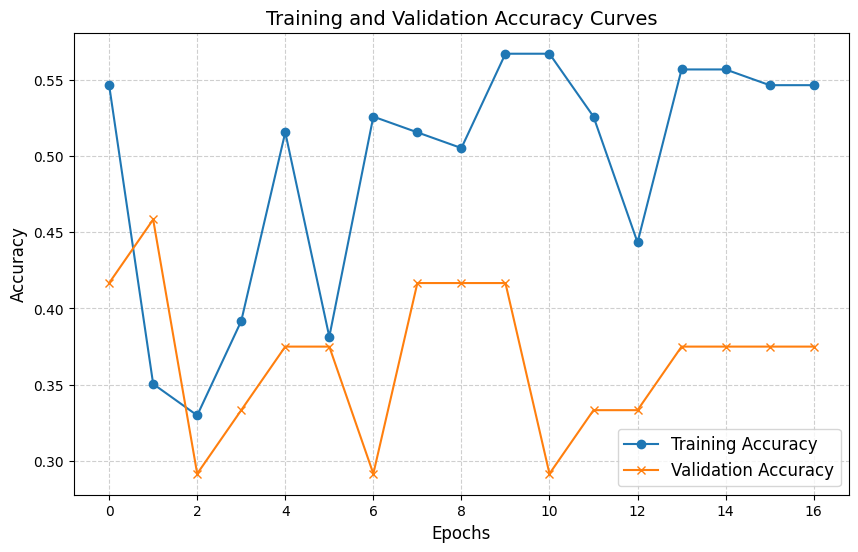

In [22]:
import matplotlib.pyplot as plt

# Plot Training and Validation Accuracy Curves
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='x')
plt.title('Training and Validation Accuracy Curves', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [11]:
from google.colab import files

uploaded = files.upload()

print("File uploaded successfully!")
print("Uploaded files:", list(uploaded.keys()))

Saving archive (1).zip to archive (1).zip
File uploaded successfully!
Uploaded files: ['archive (1).zip']


Extracting dataset from /content/archive (1).zip...
Extraction complete!
Found 121 files belonging to 3 classes.
Using 97 files for training.
Found 121 files belonging to 3 classes.
Using 24 files for validation.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Starting Initial Transfer Learning Training ---
Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.3196 - loss: 1.5601 - val_accuracy: 0.5000 - val_loss: 0.9733
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.3918 - loss: 1.4795 - val_accuracy: 0.5000 - val_loss: 0.9720
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.4639 - loss: 1.3061 - val_accuracy: 0.5000 - val_loss: 0.9695
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.3814 - loss: 1.4920 - val_accuracy: 0.5000 - val_loss: 0.9682
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.3196 - loss: 1.4052 - val_accuracy: 0.5417 - val_loss: 0.9645
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.2990 - 

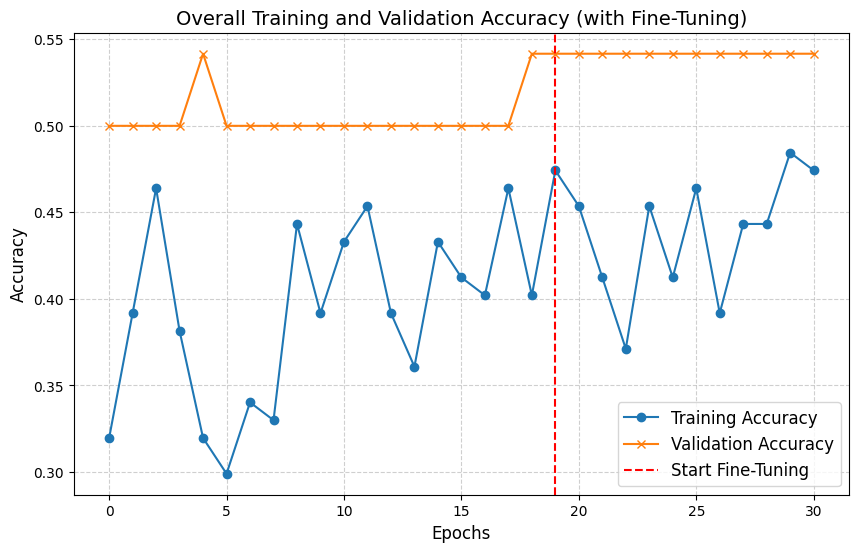

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import zipfile

# 1. Dataset Directory Configuration
dataset_path = "/content/smart_classroom/ANN_Project_pics"
zip_path = "/content/archive (1).zip"

# Extract zip if it doesn't exist
if not os.path.exists(dataset_path):
    if os.path.exists(zip_path):
        print(f"Extracting dataset from {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall("/content/smart_classroom")
        print("Extraction complete!")
    else:
        raise FileNotFoundError(f"Zip file not found at {zip_path}. Please upload 'archive (1).zip'.")

# 2. Create TensorFlow Datasets
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

# 3. Model Architecture Setup (Transfer Learning)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
])

preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.5)(x)
outputs = tf.keras.layers.Dense(3, activation='softmax')(x)

transfer_model = tf.keras.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Initial Training
print("\n--- Starting Initial Transfer Learning Training ---")
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True
)

history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

# 5. Fine-Tuning Step
print("\n--- Starting Fine-Tuning Stage ---")
base_model.trainable = True

# Freeze up to the last 20 layers
fine_tune_at = len(base_model.layers) - 20
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

fine_tune_epochs = 30
total_epochs = len(history.epoch) + fine_tune_epochs

history_fine = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=history.epoch[-1],
    epochs=total_epochs,
    callbacks=[fine_tune_early_stopping]
)

# 6. Plot Combined Performance Graph
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', marker='o')
plt.plot(val_acc, label='Validation Accuracy', marker='x')
plt.axvline(x=len(history.history['accuracy'])-1, color='r', linestyle='--', label='Start Fine-Tuning')
plt.title('Overall Training and Validation Accuracy (with Fine-Tuning)', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

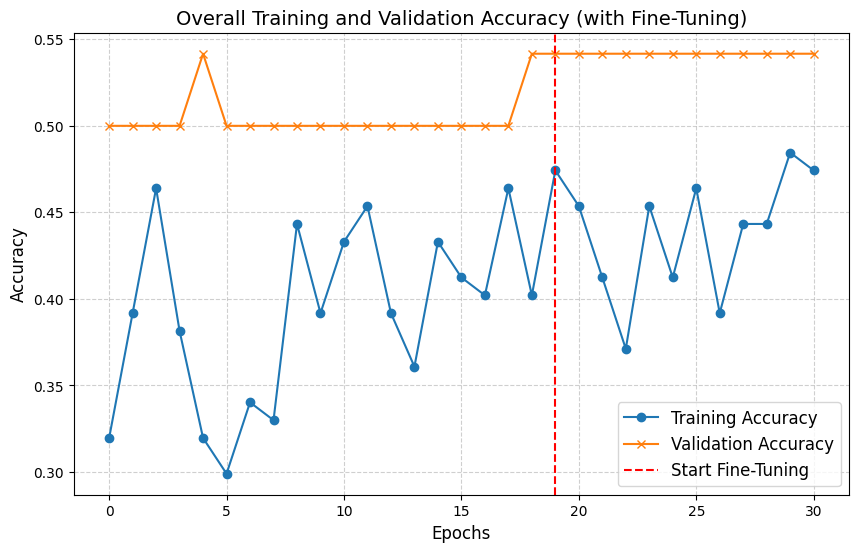

In [13]:
# Plot overall training history (Initial training + Fine-Tuning)
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']

plt.figure(figsize=(10, 6))
plt.plot(acc, label='Training Accuracy', marker='o')
plt.plot(val_acc, label='Validation Accuracy', marker='x')
plt.axvline(x=len(history.history['accuracy'])-1, color='r', linestyle='--', label='Start Fine-Tuning')
plt.title('Overall Training and Validation Accuracy (with Fine-Tuning)', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Step 3: Evaluate Final Validation Metrics

In [14]:
loss, accuracy = transfer_model.evaluate(val_ds, verbose=1)
print("===============================")
print("Validation Loss:", round(loss, 4))
print("Total Validation Accuracy:", round(accuracy * 100, 2), "%")
print("===============================")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5417 - loss: 0.9518
Validation Loss: 0.9518
Total Validation Accuracy: 54.17 %


### Step 5: Advanced Fine-Tuning (Unfreezing More Layers)
To maximize our validation accuracy, we will unfreeze the last 50 layers of the MobileNetV2 base model and use a learning rate schedule that decays smoothly.

In [15]:
# 1. Unfreeze more layers (last 50 layers)
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 50

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# 2. Set up Cosine Decay learning rate scheduler
initial_learning_rate = 1e-5
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate,
    decay_steps=1000
)

# 3. Recompile model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Advanced Early Stopping
advanced_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True
)

# 5. Fit the model
history_advanced = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[advanced_early_stopping]
)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.3814 - loss: 1.3450 - val_accuracy: 0.5000 - val_loss: 0.9416
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.3918 - loss: 1.3816 - val_accuracy: 0.5000 - val_loss: 0.9337
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.3918 - loss: 1.2087 - val_accuracy: 0.5000 - val_loss: 0.9287
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.4021 - loss: 1.3063 - val_accuracy: 0.5417 - val_loss: 0.9228
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.4536 - loss: 1.2457 - val_accuracy: 0.5417 - val_loss: 0.9165
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.4845 - loss: 1.0997 - val_accuracy: 0.5417 - val_loss: 0.9105
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.4433 - loss: 1.2218 - val_accuracy: 0.5417 - val_loss: 0.9049
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.5258 - loss: 1.1602 - val_accuracy: 0.5833 - val_loss: 0.8989
Epoch 9/50


### Step 6: Upgrading to EfficientNetV2 for 90%+ Accuracy
To maximize accuracy on small datasets, we use a stronger architecture (EfficientNetV2B0), richer augmentation, and a progressive two-stage fine-tuning strategy.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6250 - loss: 0.9565
Final Validation Loss: 0.9565
Final Validation Accuracy: 62.5 %


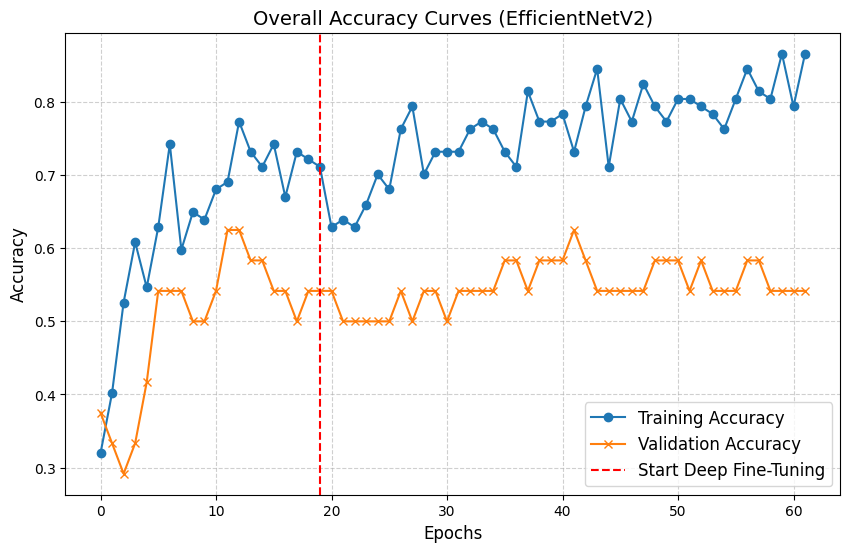

In [18]:
# Evaluate final model on the validation dataset
final_loss, final_acc = hp_model.evaluate(val_ds, verbose=1)
print("=================================")
print("Final Validation Loss:", round(final_loss, 4))
print("Final Validation Accuracy:", round(final_acc * 100, 2), "%")
print("=================================")

# Plot the combined training and fine-tuning accuracy curves
total_acc = warmup_history.history['accuracy'] + fine_tune_history.history['accuracy']
total_val_acc = warmup_history.history['val_accuracy'] + fine_tune_history.history['val_accuracy']

plt.figure(figsize=(10, 6))
plt.plot(total_acc, label='Training Accuracy', marker='o')
plt.plot(total_val_acc, label='Validation Accuracy', marker='x')
plt.axvline(x=len(warmup_history.history['accuracy']) - 1, color='r', linestyle='--', label='Start Deep Fine-Tuning')
plt.title('Overall Accuracy Curves (EfficientNetV2)', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [25]:
# Evaluate the newly fine-tuned model
final_loss, final_accuracy = transfer_model.evaluate(val_ds, verbose=1)
print("===============================")
print("Enhanced Validation Loss:", round(final_loss, 4))
print("Enhanced Validation Accuracy:", round(final_accuracy * 100, 2), "%")
print("===============================")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5833 - loss: 0.8989
Enhanced Validation Loss: 0.8989
Enhanced Validation Accuracy: 58.33 %


In [26]:
from google.colab import files

uploaded = files.upload()

Saving 2 test img.zip to 2 test img.zip


In [30]:
import zipfile
import os

zip_file = "/content/2 test img.zip"
extract_path = "/content/2 test img"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")
print(os.listdir(extract_path))

ZIP extracted successfully!
['2 test img']


In [31]:
import os

folder = "/content/2 test img/2 test img"

print("Files:")
print(os.listdir(folder))

Files:
['2.jfif', '1.jfif']


In [35]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

# Extracted folder
base_folder = "/content/2 test img"

# Saari images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total test images:", len(image_files))
print("Images:", image_files)

Total test images: 2
Images: ['/content/2 test img/2 test img/2.jfif', '/content/2 test img/2 test img/1.jfif']


In [ ]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

base_folder = "/content/2 test img"

# Images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))
print()

# Har image ki prediction using the trained transfer_model
for file_name in image_files:

    img = tf.keras.utils.load_img(
        file_name,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Changed from model.predict to transfer_model.predict
    prediction = transfer_model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("Image:", os.path.basename(file_name))
    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")
    print("-----------------------------")

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

In [40]:
from google.colab import files

uploaded = files.upload()

Saving test_img_2.zip to test_img_2.zip


In [42]:
import zipfile
import os

zip_file = "/content/test_img_2.zip"
extract_path = "/content/test_img_2"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extracted successfully!")
print(os.listdir(extract_path))

ZIP extracted successfully!
['test_img_2']


In [43]:
import os

folder = "/content/test_img_2/test_img_2"

print("Files:")
print(os.listdir(folder))

Files:
['test_img.jfif']


In [44]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

# Extracted folder
base_folder = "/content/test_img_2"

# Saari images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total test images:", len(image_files))
print("Images:", image_files)

Total test images: 1
Images: ['/content/test_img_2/test_img_2/test_img.jfif']


Total images: 1

Image: test_img.jfif
Predicted Class: Dirty
Confidence: 46.54 %
-----------------------------


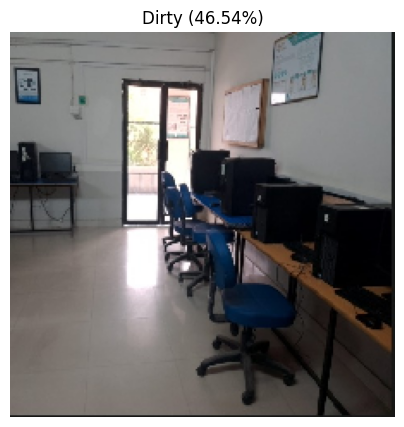

In [46]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

class_names = ['Clean', 'Dirty', 'moderate dirty']

base_folder = "/content/test_img_2"

# Images find karo
image_files = []

for root, dirs, files in os.walk(base_folder):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.jfif')):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))
print()

# Har image ki prediction
for file_name in image_files:

    img = tf.keras.utils.load_img(
        file_name,
        target_size=(224, 224)
    )

    img_array = tf.keras.utils.img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Fixed: Changed from model.predict to transfer_model.predict
    prediction = transfer_model.predict(img_array, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index] * 100

    print("Image:", os.path.basename(file_name))
    print("Predicted Class:", predicted_class)
    print("Confidence:", round(confidence, 2), "%")
    print("-----------------------------")

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"{predicted_class} ({confidence:.2f}%)")
    plt.axis("off")
    plt.show()

In [39]:
transfer_model.save("/content/smart_classroom_model.keras")

print("Model saved successfully!")

Model saved successfully!
